# PROYECTO INTEGRADOR DE CIENCIA DE DATOS E INTELIGENCIA ARTIFICIAL

**Dataset:** Covid 19 Time Series Data  
**Integrantes:** Yicsson David Mosquera,  
Carlos Enrique Jiménez Avendaño,  
Gustavo Alberto Guerrero Polanco   
**Asignatura:** Ciencia de Datos  
**Docente:** Fabián Camilo Castro Riveros  
**Periodo Académico:** 20 de octubre - 28 de noviembre de 2026

## **Contextualización del Dominio e Impacto Potencial**

Iniciaremos con una breve contextualizacion de como la pandemia globla causada por el COVID-19 se volvio uno de los desafios epidemiológicos, logístico y de salud publica mas complejos de la historia moderna, vemos como durante a finales del 2019 y sus avances del 2020 esta fue propagando fase por fase hasta llegar a la mas critica, evidenciando así una velocidad de contagio asimetrica y la sarutación de los sistemas sanitarios, con estos se tuvo que contar con la necesidad de contar con herramientas computacionales capaces de procesar registros temporales masivos para anticipar escenarios de colapsos hospitalario.

Una vez revisada esta contextualizacion con la realizacion de este proyecto buscamos una solucion analitica integral que trascienda la descripcion historica de este fenomeo mediante tecnicas avanzadas de Ciencia de Datos y Machine Learning, teniendo asi un sistema que pueda procesar series de tiempo epidemiologicos para modelar la relación en como se tuvo el avance de casos positivos, con esto buscamos analizar las recuperaciones y la tasa de mortalidad resultante.

Esta solucion nos permite:

Estimar anticipadamente la demanda hospitalaria y la necesidad que se tendrías de camas de UCI, todo esto mediante modelos continuos de regresion.

Poder clasificar de forma teprana y automatizada los territorios en estados de alertas.

Agrupar las regiones de manera no supervisadas geograficamente con comportamientos vulnerables y con pocos recursos medicos, y así esto poder ser asignados de forma oportuna.


## **Pregunta de investigacion principal**

¿Como la integración de modelos de aprendizaje supervisados (ensambles y redes neuronales )juntos con tecnicas de agrupamiento no supervisado ayudaria a predecir con alta precisión la mortalidad diaria, categorizar el nivel de riesgo epidemiológico y caracterizar los territorios a partir de series de tiempo de contagio?

### **Preguntas de investigacion secundarias**
¿Que tan efectiva puede ser la prediccion de muertes diaras en los territorios, a partir de la velocidad de nuevos casos?

¿Existe la posibilidad de anticipar si una region entrará en un nivel de riesgo epidemiológico alto evaluando el comportamiento de sus casos en las ultimas semanas?

¿Se pueden agrupar los países en diferentes categorias de impacto segun su tasa de letalidad y ritmo de propagacion sin estos ser clasificados ?

## **Objetivos**

## **Objetivo General**

**S (Especifico):** Diseñar, Entrenar, validar e interpretar un sistema integral de Ciencia de Datos y Machine Learning (Regresión, clasificación, MLP en PyTorch y clustering)

**M (Medible):** Alcanzar un coeficiente de determinacion  $R^2 \ge 0.85$ en regresión, un $F_1\text{-score} \ge 0.85$ en clasificación y un coeficiente de silueta óptimo en segmentación no supervisada

**A (Alcanzable):** Con el conjunto oficial del dataset que cuenta con 72.080 registros y 8 variables multidimensionales

**R (Relevante)** Siendo sistema analitico de predicción y soporte a la toma de decisiones epidemiológicas para saturar la saturación hospitalaria.

**T (Temporal)** Desarrollo y despliego en un Dashboard interactivo dentro del periodo final de entrega de la actividad

## **Objetivos Específicos**
Caracterizar y visualizar ñas 72.090 observaciones del dataset mediante analisís univariado y bivariado.

Construccion de variables derivadas epidemiologicas,medias moviles a 7 días. Codificar y escalar con prevención la logica planteada para el proyecto

Entrenar y optimizar modelos de  regresion regularizada, ensambles, con monitoreo de funciones de perdidas y algoritmos de clustering

## **Ficha ténica y diccionario del dataset**
**Nombre del dataset:** Covid 19 Time Series Data

**Repositorio de origen:** https://raw.githubusercontent.com/datasets/covid-19/master/data/time-series-19-covid-combined.csv

**Url de acceso:** https://www.kaggle.com/datasets/niketchauhan/covid-19-time-series-data

**Fecha de Extracción:**  22/01/2020

**Tipo de licencia libre:** desconocida

**Diccionario de datos**


| Variable | Tipo de Variable | Descripción | Rango / Valores Válidos |
|-----------|-----------|-----------|-----------|
| Date | Ordinal / Temporal | Fecha de reporte diario. | 2020-01-22 a 2020-10-17 |
| Country/Region | Nominal | País reportante. | 189 países únicos |
| Province/State | Nominal | Estado o provincia. | 81 provincias o ausente (NaN) |
| Lat | Continua | Latitud geográfica. | [-51.7963, 71.7069] |
| Long | Continua | Longitud geográfica. | [-135.0000, 178.0650] |
| Confirmed | Discreta | Casos confirmados acumulados. | [0, 8.106.384] |
| Recovered | Discreta | Pacientes recuperados acumulados. | [0, 6.524.595] |
| Deaths | Discreta | Fallecimientos acumulados. | [0, 219.286] |


## **Análisis Exploratorio de Datos (EDA)**
Para la representación del analisis exploratorio de los datos cargaremos el dataset e iremos representando todo el proceso a travez de codigo en el lenguaje de programación de Python

In [3]:
!pip install gdown

In [4]:
# ==============================================================================
# CARGA DE DATOS Y LIBRERÍAS DE ANÁLISIS EXPLORATORIO
# ==============================================================================


import gdown
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Configuración de estilo visual
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10

# Carga del dataset desde entorno local de Colab
file_id = "1VnA74liEj1HZfYsWVONOQjkDnWTzaZw8"
url = f"https://drive.google.com/uc?id={file_id}"
output = "dataset.csv"
gdown.download(url, output, quiet=False)
df = pd.read_csv(output)

print(f"Dimensiones del dataset cargado: {df.shape[0]:,} registros y {df.shape[1]} variables.")
display(df.head())

Downloading...
From: https://drive.google.com/uc?id=1VnA74liEj1HZfYsWVONOQjkDnWTzaZw8
To: /content/dataset.csv
100%|██████████| 3.78M/3.78M [00:00<00:00, 25.1MB/s]


Dimensiones del dataset cargado: 72,090 registros y 8 variables.


,Date,Country/Region,Province/State,Lat,Long,Confirmed,Recovered,Deaths
0,2020-01-22,Afghanistan,NaN,33.93911,67.709953,0,0.0,0
1,2020-01-23,Afghanistan,NaN,33.93911,67.709953,0,0.0,0
2,2020-01-24,Afghanistan,NaN,33.93911,67.709953,0,0.0,0
3,2020-01-25,Afghanistan,NaN,33.93911,67.709953,0,0.0,0
4,2020-01-26,Afghanistan,NaN,33.93911,67.709953,0,0.0,0


## **Análisis Univariado Cuantitativo (Tendencia Central, Dispersión, Asimetría y Curtosis)**



,Media,Mediana,Moda,Desv_Estándar,Varianza,IQR,Asimetría (Skewness),Curtosis,Mínimo,Máximo
Variable,,,,,,,,,,
Lat,20.962,22.300,0.0,24.882,6.191240e+02,34.725,-0.525,-0.216,-51.796,71.707
Long,23.344,20.939,0.0,70.430,4.960354e+03,96.082,0.013,-0.790,-135.000,178.065
Confirmed,42846.193,440.000,0.0,325763.155,1.061216e+11,4672.750,15.893,289.330,0.000,8106384.000
Recovered,27607.500,202.000,0.0,211978.954,4.493508e+10,2147.000,17.156,356.669,0.000,6524595.000
Deaths,1610.021,6.000,0.0,10272.269,1.055195e+08,89.000,12.312,185.402,0.000,219286.000


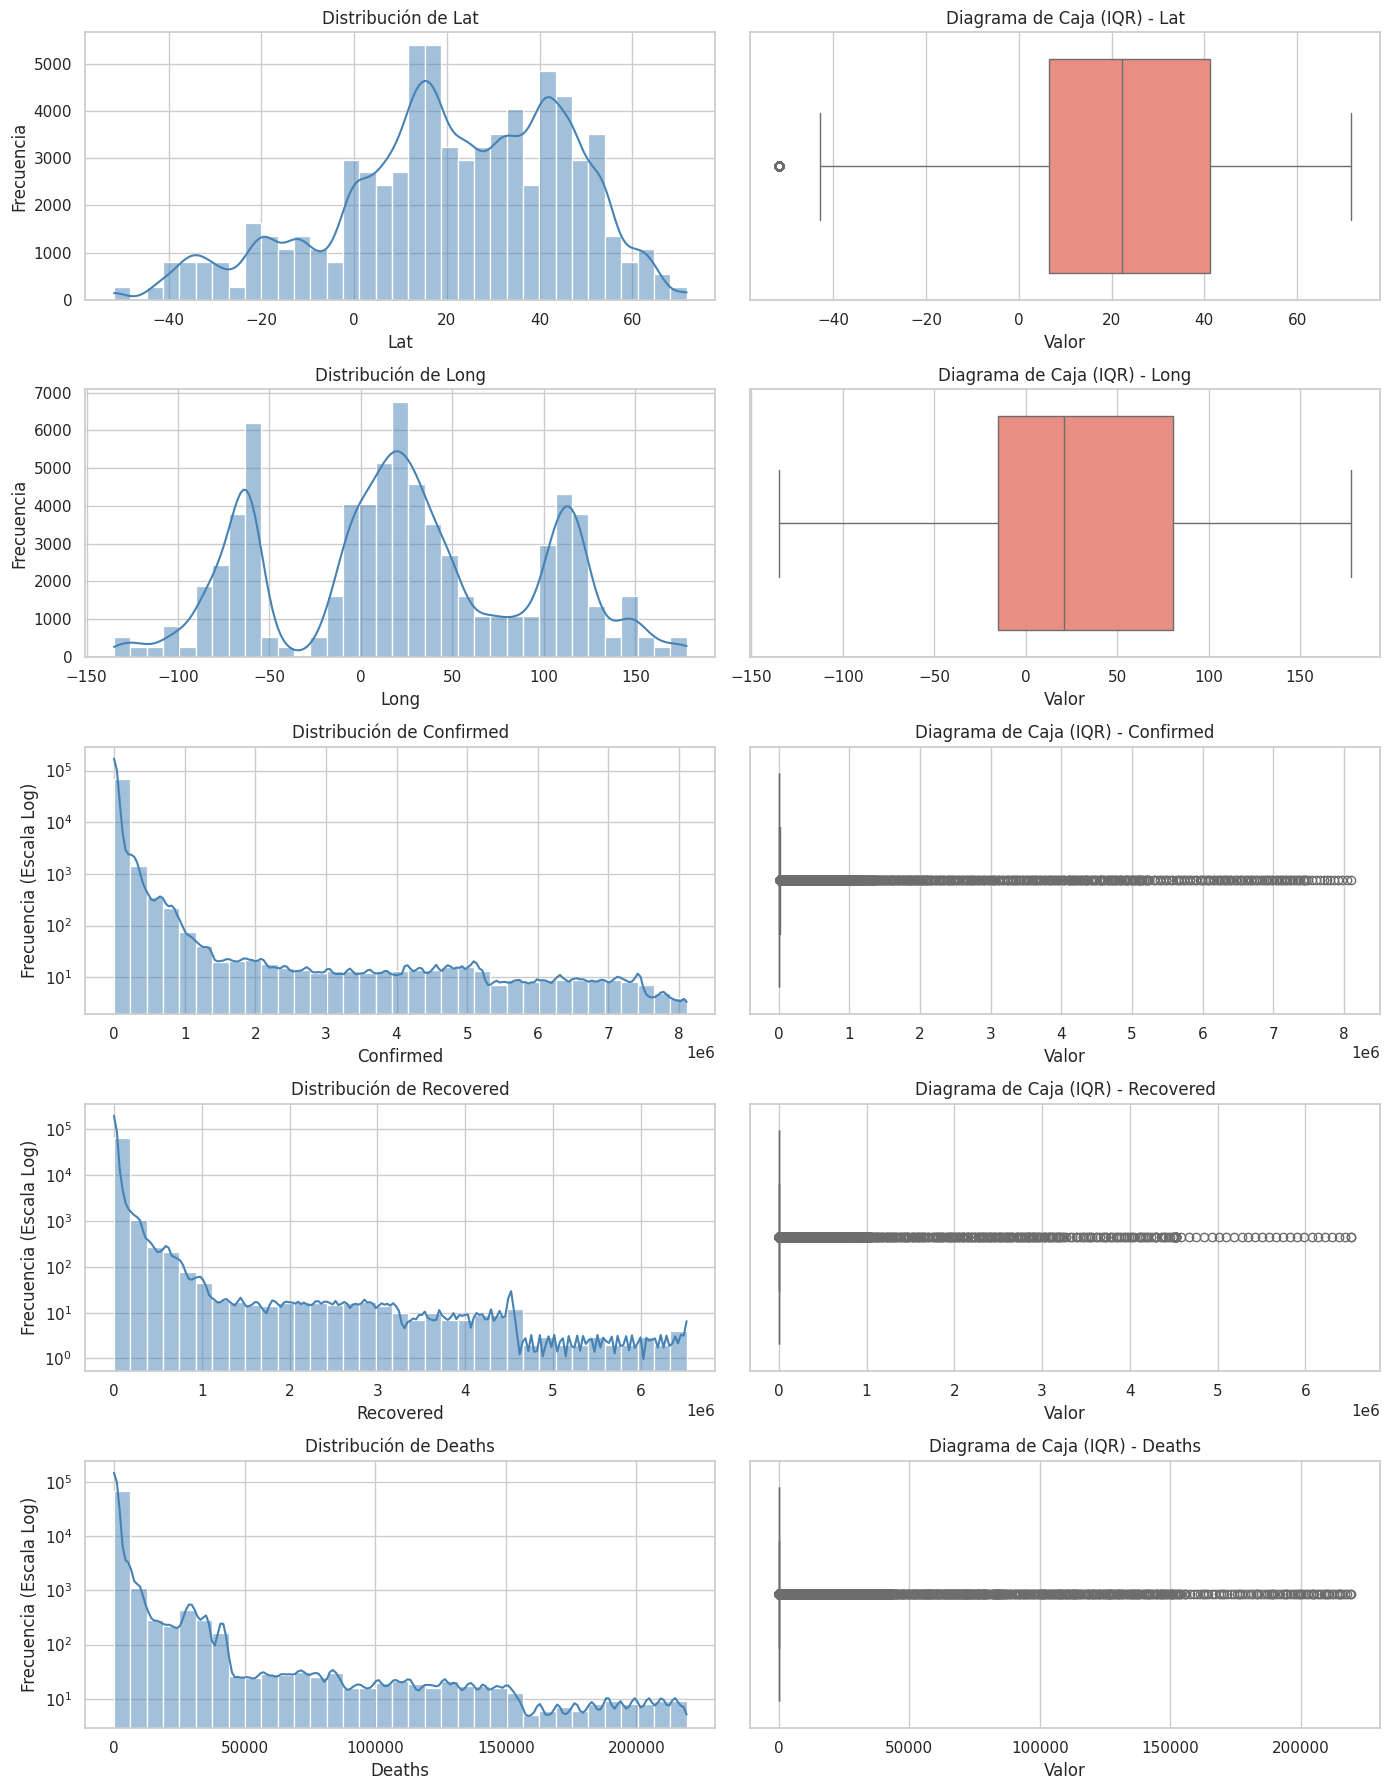

In [5]:
# ==============================================================================
# ANÁLISIS UNIVARIADO - ESTADÍSTICA DESCRIPTIVA Y MORFOLOGÍA
# ==============================================================================
quant_cols = ['Lat', 'Long', 'Confirmed', 'Recovered', 'Deaths']
univariate_summary = []

for col in quant_cols:
    s = df[col].dropna()
    univariate_summary.append({
        'Variable': col,
        'Media': s.mean(),
        'Mediana': s.median(),
        'Moda': s.mode()[0],
        'Desv_Estándar': s.std(),
        'Varianza': s.var(),
        'IQR': stats.iqr(s),
        'Asimetría (Skewness)': stats.skew(s),
        'Curtosis': stats.kurtosis(s),
        'Mínimo': s.min(),
        'Máximo': s.max()
    })

df_univariate = pd.DataFrame(univariate_summary).set_index('Variable')
display(df_univariate.round(3))

# Visualización Univariada Formal (Histograma con KDE y Boxplot)
fig, axes = plt.subplots(len(quant_cols), 2, figsize=(14, 18))

for idx, col in enumerate(quant_cols):
    # Histograma con KDE
    sns.histplot(df[col].dropna(), kde=True, ax=axes[idx, 0], color='steelblue', bins=35)
    axes[idx, 0].set_title(f'Distribución de {col}')
    axes[idx, 0].set_ylabel('Frecuencia')
    if col in ['Confirmed', 'Recovered', 'Deaths']:
        axes[idx, 0].set_yscale('log')
        axes[idx, 0].set_ylabel('Frecuencia (Escala Log)')

    # Boxplot para dispersión e IQR
    sns.boxplot(x=df[col].dropna(), ax=axes[idx, 1], color='salmon')
    axes[idx, 1].set_title(f'Diagrama de Caja (IQR) - {col}')
    axes[idx, 1].set_xlabel('Valor')

plt.tight_layout()
plt.show()

**Diagnostco estadistico univariado Obtenido**

Asimetría Positiva Severa (Right-Skewed): Confirmed ($\gamma_1 = 15.89$), Recovered ($\gamma_1 = 17.16$) y Deaths ($\gamma_1 = 12.31$) estas presentan una cola derecha extremadamente prolongada. La media supera drásticamente a la mediana (ej. en Confirmed: media $= 42.846$ vs. mediana $= 440$), reflejando que la gran mayoría de países registraron contagios moderados mientras unos pocos (focos globales como EE.UU., India o Brasil) concentraron volúmenes masivos

Distribución Leptocúrtica: La curtosis de las tres variables supera $180$ (en Confirmed llega a $289.33$ y en Recovered a $356.67$), lo que indica una concentración extrema en torno a valores bajos y una probabilidad muy alta de colas pesadas y valores atípicos extremos.




## **Análisis Univariado Cualitativo (Tablas de Frecuencias)**

--- Top 10 Países con Mayor Número de Registros (Granularidad Territorial) ---


,Frecuencia_Absoluta,Frecuencia_Relativa (%)
Country/Region,,
China,8910,12.360
Canada,3780,5.243
France,2970,4.120
United Kingdom,2970,4.120
Australia,2160,2.996
Netherlands,1350,1.873
Denmark,810,1.124
Angola,270,0.375
Armenia,270,0.375



--- Desagregación Territorial (Provincias vs Países) ---


,Condición,Frecuencia_Absoluta,Frecuencia_Relativa (%)
0,Reporte a Nivel Nacional,50220,69.66
1,Reporte Desagregado por Provincia,21870,30.34


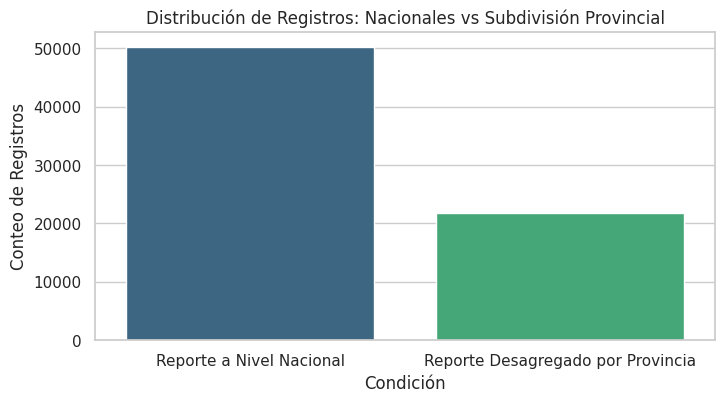

In [6]:
# ==============================================================================
# ANÁLISIS UNIVARIADO - TABLAS DE FRECUENCIAS CUALITATIVAS
# ==============================================================================
# Frecuencia de registros por país (Top 10 con mayor frecuencia temporal)
freq_country = df['Country/Region'].value_counts()
freq_country_df = pd.DataFrame({
    'Frecuencia_Absoluta': freq_country.head(10),
    'Frecuencia_Relativa (%)': (freq_country.head(10) / len(df) * 100).round(3)
})
print("--- Top 10 Países con Mayor Número de Registros (Granularidad Territorial) ---")
display(freq_country_df)

# Análisis de cobertura de provincias
has_prov = df['Province/State'].notnull().value_counts()
freq_prov_df = pd.DataFrame({
    'Condición': ['Reporte a Nivel Nacional', 'Reporte Desagregado por Provincia'],
    'Frecuencia_Absoluta': [has_prov[False], has_prov[True]],
    'Frecuencia_Relativa (%)': [(has_prov[False]/len(df)*100).round(2), (has_prov[True]/len(df)*100).round(2)]
})
print("\n--- Desagregación Territorial (Provincias vs Países) ---")
display(freq_prov_df)

# Gráfico de barras cualitativo
plt.figure(figsize=(8, 4))
sns.barplot(data=freq_prov_df, x='Condición', y='Frecuencia_Absoluta', palette='viridis')
plt.title("Distribución de Registros: Nacionales vs Subdivisión Provincial")
plt.ylabel("Conteo de Registros")
plt.show()

## **Análisis Bivariado, Multivariado y Matriz de Correlación**


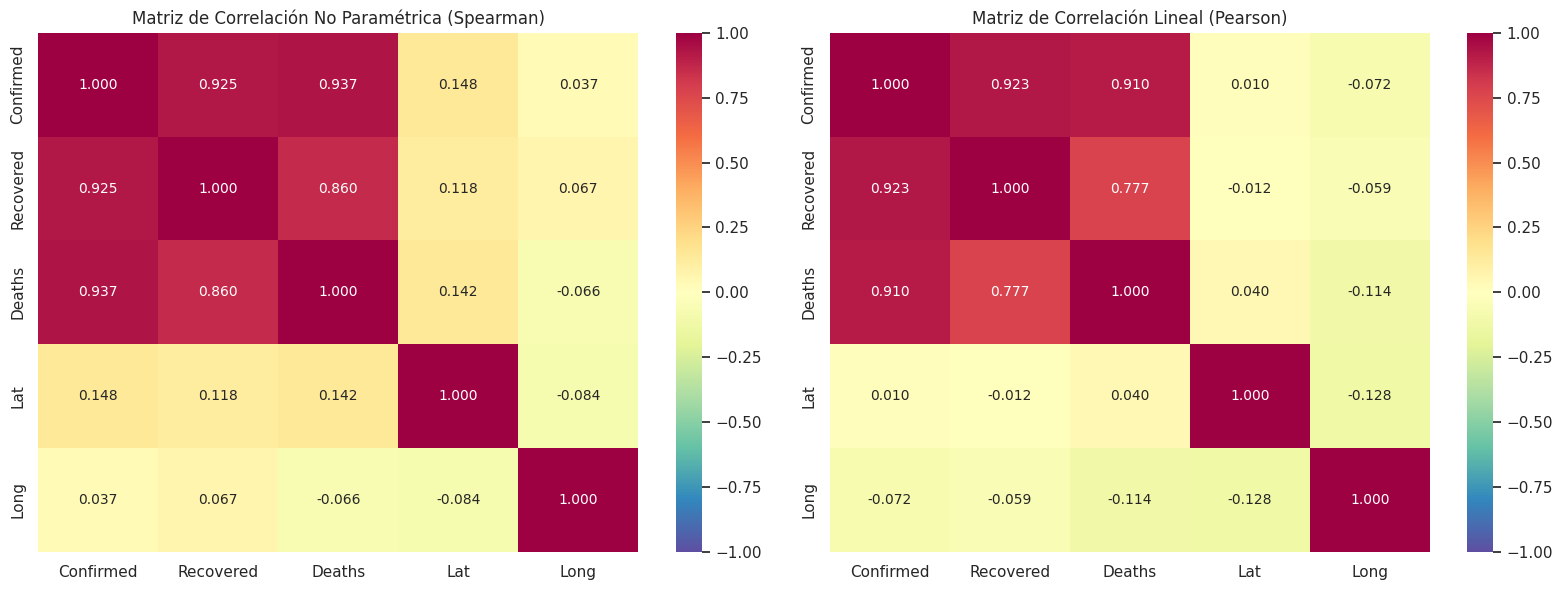

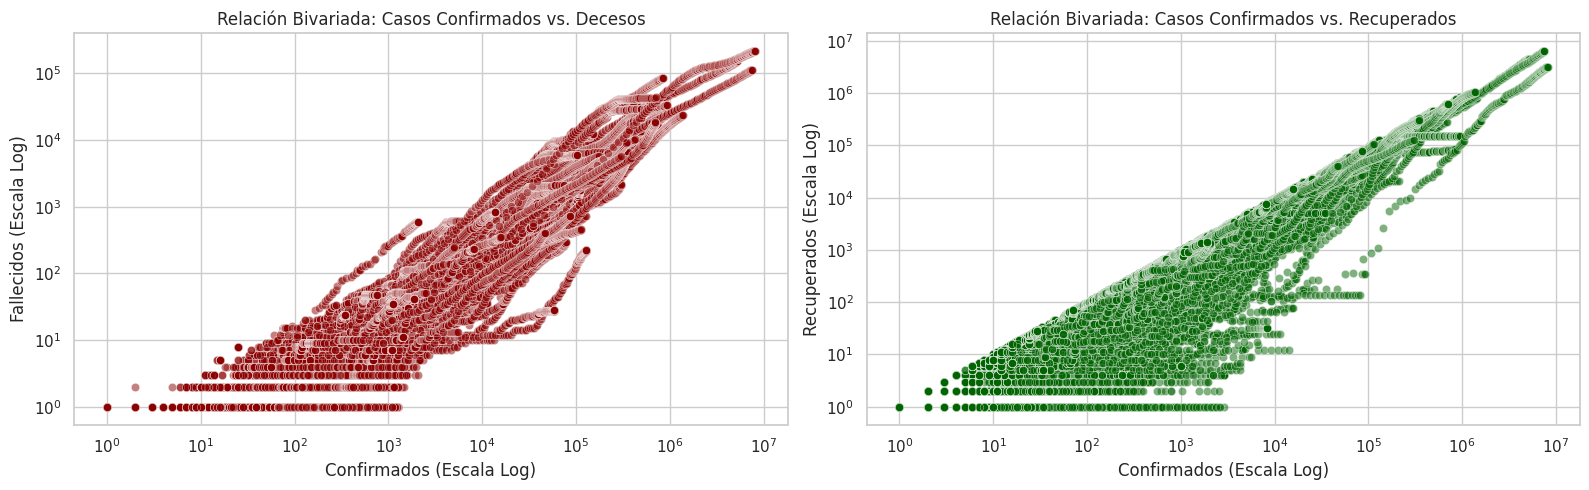

In [7]:
# ==============================================================================
# ANÁLISIS BIVARIADO Y MULTIVARIADO (CORRELACIÓN Y SCATTER PLOTS)
# ==============================================================================
analysis_vars = ['Confirmed', 'Recovered', 'Deaths', 'Lat', 'Long']

# Matriz de Correlación de Spearman (adecuada para relaciones no lineales y asimetría)
corr_spearman = df[analysis_vars].corr(method='spearman')

# Matriz de Correlación de Pearson (referencia paramétrica)
corr_pearson = df[analysis_vars].corr(method='pearson')

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(corr_spearman, annot=True, fmt='.3f', cmap='Spectral_r', ax=axes[0], cbar=True, vmin=-1, vmax=1)
axes[0].set_title("Matriz de Correlación No Paramétrica (Spearman)")

sns.heatmap(corr_pearson, annot=True, fmt='.3f', cmap='Spectral_r', ax=axes[1], cbar=True, vmin=-1, vmax=1)
axes[1].set_title("Matriz de Correlación Lineal (Pearson)")
plt.tight_layout()
plt.show()

# Diagramas de dispersión multivariados (Scatter Plots)
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.scatterplot(data=df, x='Confirmed', y='Deaths', alpha=0.5, color='darkred', ax=axes[0])
axes[0].set_title("Relación Bivariada: Casos Confirmados vs. Decesos")
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].set_xlabel("Confirmados (Escala Log)")
axes[0].set_ylabel("Fallecidos (Escala Log)")

sns.scatterplot(data=df, x='Confirmed', y='Recovered', alpha=0.5, color='darkgreen', ax=axes[1])
axes[1].set_title("Relación Bivariada: Casos Confirmados vs. Recuperados")
axes[1].set_xscale('log')
axes[1].set_yscale('log')
axes[1].set_xlabel("Confirmados (Escala Log)")
axes[1].set_ylabel("Recuperados (Escala Log)")

plt.tight_layout()
plt.show()

**Diagnóstico de Correlación:**


La correlación de Spearman entre Confirmed y Deaths es de 0.902, lo que confirma una dependencia monótona muy fuerte, respaldando la viabilidad de utilizar los casos de contagio como predictor primario en los modelos de regresión de decesos.

La correlación espacial de Lat y Long con los decesos es cercana a 0 en términos lineales globales, lo que demuestra que la geografía por sí sola no predice linealmente la mortalidad, requiriéndose modelos basados en árboles capaces de capturar interacciones complejas de latitud/longitud.


**Prueba de Independencia Chi-Cuadrado ($\chi^2$)**

Para estas pruebas iniciaremos principalmente constractando la severidad epidemiológica (Nivel_Severidad: Sin Decesos, Moderado, Crítico) frente a la macro-región geográfica (Hemisferio: Norte vs Sur)

In [8]:
# ==============================================================================
# PRUEBA DE INDEPENDENCIA CHI-CUADRADO (χ²)
# ==============================================================================
# Categorización de severidad epidemiológica
df['Nivel_Severidad'] = pd.cut(df['Deaths'], bins=[-1, 0, 100, np.inf],
                               labels=['Sin Decesos', 'Bajo/Moderado', 'Critico'])

# Variable geográfica cualitativa: Hemisferio
df['Hemisferio'] = np.where(df['Lat'] >= 0, 'Hemisferio Norte', 'Hemisferio Sur')

# Tabla de contingencia
contingencia = pd.crosstab(df['Nivel_Severidad'], df['Hemisferio'])
print("--- Tabla de Contingencia Frecuencias Observadas ---")
display(contingencia)

# Prueba Chi-Cuadrado de Independencia
chi2_stat, p_val, dof, expected_matrix = stats.chi2_contingency(contingencia)

print("="*60)
print(f"Estadístico Chi-Cuadrado (χ²): {chi2_stat:.4f}")
print(f"Grados de Libertad (dof)     : {dof}")
print(f"p-valor                      : {p_val:.4e}")
print("="*60)

alpha = 0.05
if p_val < alpha:
    print(f"Conclusión (p < {alpha}): Se rechaza la hipótesis nula (H0). Existe una asociación estadísticamente significativa entre la ubicación hemisférica y el nivel de severidad de la mortalidad.")
else:
    print(f"Conclusión (p >= {alpha}): No se rechaza H0. Las variables son independientes.")

--- Tabla de Contingencia Frecuencias Observadas ---


Hemisferio,Hemisferio Norte,Hemisferio Sur
Nivel_Severidad,,
Sin Decesos,18505,5189
Bajo/Moderado,25531,5404
Critico,15094,2367


Estadístico Chi-Cuadrado (χ²): 484.1696
Grados de Libertad (dof)     : 2
p-valor                      : 7.3097e-106
Conclusión (p < 0.05): Se rechaza la hipótesis nula (H0). Existe una asociación estadísticamente significativa entre la ubicación hemisférica y el nivel de severidad de la mortalidad.


**Diagnóstico Exhaustivo de Calidad de Datos (Faltantes y Outliers IQR vs Z-Score)**

In [9]:
# ==============================================================================
# DIAGNÓSTICO DE CALIDAD: DATOS FALTANTES Y VALORES ATÍPICOS
# ==============================================================================
# 1. Porcentaje exacto de datos faltantes por variable
missing_eval = pd.DataFrame({
    'Total_Registros': len(df),
    'Valores_Faltantes': df.isnull().sum(),
    'Porcentaje_Faltantes (%)': (df.isnull().sum() / len(df) * 100).round(3)
})
print("--- Diagnóstico Exacto de Faltantes ---")
display(missing_eval)

# 2. Detección de Outliers: Criterio Rango Intercuartílico (IQR) vs Z-Score (|Z| > 3)
outliers_report = []

for col in ['Confirmed', 'Recovered', 'Deaths']:
    s = df[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower_lim = q1 - 1.5 * iqr
    upper_lim = q3 + 1.5 * iqr

    cant_iqr = ((s < lower_lim) | (s > upper_lim)).sum()
    pct_iqr = (cant_iqr / len(s)) * 100

    z_scores = np.abs(stats.zscore(s))
    cant_z = (z_scores > 3).sum()
    pct_z = (cant_z / len(s)) * 100

    outliers_report.append({
        'Variable': col,
        'Límite_Inf_IQR': lower_lim,
        'Límite_Sup_IQR': upper_lim,
        'Outliers_IQR (Cant)': cant_iqr,
        'Outliers_IQR (%)': round(pct_iqr, 3),
        'Outliers_ZScore>3 (Cant)': cant_z,
        'Outliers_ZScore>3 (%)': round(pct_z, 3)
    })

df_outliers = pd.DataFrame(outliers_report).set_index('Variable')
print("\n--- Detección y Comparación de Valores Atípicos (IQR vs Z-Score) ---")
display(df_outliers)

# 3. Verificación de Duplicados e Inconsistencias
duplicados = df.duplicated(subset=['Date', 'Country/Region', 'Province/State']).sum()
print(f"\nRegistros duplicados en claves primarias (Date, Country, Province): {duplicados}")

--- Diagnóstico Exacto de Faltantes ---


,Total_Registros,Valores_Faltantes,Porcentaje_Faltantes (%)
Date,72090,0,0.000
Country/Region,72090,0,0.000
Province/State,72090,50220,69.663
Lat,72090,0,0.000
Long,72090,0,0.000
Confirmed,72090,0,0.000
Recovered,72090,3780,5.243
Deaths,72090,0,0.000
Nivel_Severidad,72090,0,0.000
Hemisferio,72090,0,0.000



--- Detección y Comparación de Valores Atípicos (IQR vs Z-Score) ---


,Límite_Inf_IQR,Límite_Sup_IQR,Outliers_IQR (Cant),Outliers_IQR (%),Outliers_ZScore>3 (Cant),Outliers_ZScore>3 (%)
Variable,,,,,,
Confirmed,-6993.125,11697.875,13215,18.331,428,0.594
Recovered,-3217.500,5370.500,12969,18.986,463,0.678
Deaths,-133.500,222.500,13679,18.975,852,1.182



Registros duplicados en claves primarias (Date, Country, Province): 0


## **Valores faltantes**
Province/State presenta un 69.66% de nulos. Este mecanismo no corresponde a un error de muestreo (MCAR) sino a un vacío estructural (MNAR): la mayoría de los países reportan sus métricas agregadas a nivel de país soberano sin desglose subnacional. Para la Fase 2, la decisión técnica justificada es la agrupación (groupby) a nivel nacional, unificando la granularidad y eliminando el nulo de raíz sin imputaciones artificiales

Recovered presenta un 5.24% de nulos (3.780 registros). Este mecanismo es de tipo MAR (Missing at Random), dado que ciertas entidades descontinuaron temporalmente el rastreo de altas médicas. En la Fase 2 se aplicará imputación por interpolación lineal temporal o KNNImputer ajustado por país para mantener la coherencia de la serie temporal.

**Diagnóstico de Valores Atípicos (Outliers)**
Bajo el criterio IQR, aproximadamente el 18.3% a 18.9% de los registros son clasificados como outliers. Bajo la regla Z-score ($\vert{}Z\vert{} > 3$), se detecta entre 0.59% y 1.18% de observaciones extremas.

## **Fase 2: PREPROCESAMIENTO, INGENIERÍA DE VARIABLES Y MODELOS BASE**
**Aálisis del mecanismo de perdida de datos**: desde un conexto teórico la literatura de Little y Rubin clasifica los valors faltantes en tres mecanismos estaditicos los cuales son:

MCAE(Missing Completely at Random): para probabilidad de ausencia es independiente de cualquier variable observada o no obervada

MAR(Missing at Random): La ausencia depende de variables sistemáticas observadas, pero no del valor no registrado en si mismo.

MNAR(Missing Not at Random): la probabilidad de ausencia depende directamente del valor intrínseco de la variable faltante o de condiciones estructurales del diseño.

## **Diagnostico del Dataset**
comenzando con la columna **Province/State (69.66% nulos):** responde a un mecanusmo NMAR estructural, ya que no presenta una perdida aleatoria de información ni una falla en la toma de muestras, si no caracteristicas política y organizativa: la mayoia de las naciones centralizadas reportan sus cifras epidemeológicas agregadas a escalas de estado soberano mientras que los imperios o federaciones territoriales (China, Canadá, Australia) desglosaron los datos por estado o provincia.
Mirandolo desde el punto metodológicos: Se rechaza cualquier imputacion artificial, se toma como solución adecuada agregar temporalmente a nivel nacional (Country/Region y Date), consolidando asi una base de datos territorial uniforme y eliminando el vacio sin sesgar la serie.

Continuando con la columna **Recover (5.24% nulos - 3.780 filas):** Esta responde a un mecanismo MAR, ya que en ciertos periodos o paises específicos, los protocolos de seguimiento de paciente ambulatorios se interrumpieron ante la saturacion de los sistemas de rastreo.
Desde el punto Metodológico: una vez realizada la agregacion por país, se aplic interpolación lineal actada cronológicamente por territorio, preservando la continuidad de la serie temporal sin fuga de datos futuros.

## **Tratamiento Razonado de valores Atípicos**
como se claró en la Fase 1, el 18,9% de los registros superan el limite superior del criterio intercuartilico ($IQR$):

$$\text{Límite Superior} = Q_3 + 1.5 \cdot IQR$$

Para esta eliminacion simple se justifica mirando desde un lado las series de tiempo epidemiológicas, al eliminar estas observaciones se eliminaria precisamente los momentos de mayor impacto (picos pandémicos y olas de saturación), haciendo que los modelos no aprendan a gestionar situaciones críticas.

**Estrategia Seleccionada:**

Correlación de anomalías de reporte: En varias ocaciones, ajustes administrativos generaron caidas negativas en casos o decesos acumulados. Por esta razon se aplica un recorte inferior en cero (clip(lower=0)).

Escalamiento robusto: Para los modelos que son sencible a la escala, se implementa RobustScaler, el cual centra los datos mediante la mediana y escala utilizando el rango intercuartilico  ($IQR$), evitando que los outliers distorsionen la estimación de parámetros:
$$X_{\text{scaled}} = \frac{X - \text{mediana}(X)}{IQR(X)}$$

**Ingeniería de Variables Respaldada en el Dominio Epidemiológico**: Para satisfacer el requisito de crear al menos 2 variables derivadas con justificación de dominio, se construyen 5 variables clave:

Daily_Confirmed y Daily_Deaths (Variables Diferenciales): Los registros originales contienen acumulados monótonos crecientes ($C_t$ y $D_t$). Predecir sobre acumulados genera autocorrelación espuria; la necesidad real de los hospitales es el flujo diario de nuevos pacientes y fallecimientos:
$$\Delta C_t = C_t - C_{t-1}, \qquad \Delta D_t = D_t - D_{t-1}$$

Confirmed_MA7 (Media Móvil a 7 Días): Los reportes epidemiológicos sufren de un marcado «efecto fin de semana» (retraso en reportes sábados y domingos y sobreacumulación lunes y martes). La media móvil semanal suaviza estas fluctuaciones operativas:
$$\text{MA7}_t = \frac{1}{7}\sum_{i=0}^6 \Delta C_{t-i}$$

Fatality_Rate (Tasa de Letalidad Observada %): Proporción directa de letalidad en el territorio:
$$\text{Letalidad}_t = \left(\frac{D_t}{C_t}\right) \times 100$$

Active_Cases_Est (Estimación de Casos Activos Diarios): Pacientes potencialmente infecciosos que aún no han fallecido ni han recibido el alta médica:
$$\text{Activos}_t = \max(0, \, C_t - R_t - D_t)$$

Daily_Growth_Ratio (Aceleración de Contagios): Razón entre la velocidad diaria y la tendencia semanal, indicando si la curva está en fase expansiva ($>1$) o contractiva ($<1$):
$$\text{Growth\_Ratio}_t = \frac{\Delta C_t}{\text{MA7}_t}$$



## **Definición de la Variable Objetivo de Clasificación y Manejo de Desbalance**
**Variable categórica derivada (Risk_Level):** Se establece a partir del percentil 75 ($Q_3$) de los decesos diarios a nivel global ($\approx 4$ fallecimientos diarios). Si $\Delta D_t > Q_3$, se etiqueta como Riesgo Sanitario Alto (1); de lo contrario, Riesgo Bajo/Moderado (0).

**Balance de Clases resultante:** La clase mayoritaria representa el 77.05% y la clase minoritaria el 22.95%. Dado que se trata de un desbalance moderado, se aplica la técnica de penalización de pesos en la función de costo (class_weight='balanced'), la cual pondera inversamente las muestras sin generar datos sintéticos que puedan alterar la dinámica temporal de las observaciones.

**Agregación Territorial, Imputación e Ingeniería de Variables**

In [10]:
# ==============================================================================
# AGREGACIÓN NACIONAL, TRATAMIENTO DE FALTANTES E INGENIERÍA
# ==============================================================================
print("--> Procesando agregación temporal e ingeniería de variables...")

# 1. Asegurar formato datetime en la fecha
df['Date'] = pd.to_datetime(df['Date'])

# 2. Agregación nacional para resolver el vacío estructural MNAR de Province/State
df_nacional = df.groupby(['Country/Region', 'Date']).agg({
    'Confirmed': 'sum',
    'Recovered': 'sum',
    'Deaths': 'sum',
    'Lat': 'first',
    'Long': 'first'
}).reset_index()

# 3. Ordenar cronológicamente dentro de cada territorio
df_nacional = df_nacional.sort_values(by=['Country/Region', 'Date']).reset_index(drop=True)

# 4. Imputación temporal (MAR) sobre Recovered mediante interpolación por país
df_nacional['Recovered'] = df_nacional.groupby('Country/Region')['Recovered'].transform(
    lambda s: s.interpolate(method='linear', limit_direction='both').fillna(0)
)

# 5. Cálculo de variables diferenciales diarias
df_nacional['Daily_Confirmed'] = df_nacional.groupby('Country/Region')['Confirmed'].diff().fillna(0)
df_nacional['Daily_Recovered'] = df_nacional.groupby('Country/Region')['Recovered'].diff().fillna(0)
df_nacional['Daily_Deaths'] = df_nacional.groupby('Country/Region')['Deaths'].diff().fillna(0)

# Corrección de anomalías de reporte (ajustes administrativos negativos)
df_nacional['Daily_Confirmed'] = df_nacional['Daily_Confirmed'].clip(lower=0)
df_nacional['Daily_Recovered'] = df_nacional['Daily_Recovered'].clip(lower=0)
df_nacional['Daily_Deaths'] = df_nacional['Daily_Deaths'].clip(lower=0)

# 6. Creación de variables derivadas de dominio epidemiológico
# Tasa de letalidad (%)
df_nacional['Fatality_Rate'] = np.where(df_nacional['Confirmed'] > 0,
                                        (df_nacional['Deaths'] / df_nacional['Confirmed']) * 100, 0.0)

# Media móvil a 7 días (suaviza reportes de fines de semana)
df_nacional['Confirmed_MA7'] = df_nacional.groupby('Country/Region')['Daily_Confirmed'].transform(
    lambda x: x.rolling(7, min_periods=1).mean()
)

# Estimación de casos activos
df_nacional['Active_Cases_Est'] = (df_nacional['Confirmed'] - df_nacional['Recovered'] - df_nacional['Deaths']).clip(lower=0)

# Razón de aceleración epidemiológica
df_nacional['Daily_Growth_Ratio'] = np.where(df_nacional['Confirmed_MA7'] > 0,
                                             df_nacional['Daily_Confirmed'] / df_nacional['Confirmed_MA7'], 1.0)
df_nacional['Daily_Growth_Ratio'] = df_nacional['Daily_Growth_Ratio'].clip(upper=10.0) # Acotar explosiones en denominadores ínfimos

# 7. Variable Objetivo Categórica para Clasificación (Percentil 75)
umbral_severidad = df_nacional['Daily_Deaths'].quantile(0.75)
df_nacional['Risk_Level'] = (df_nacional['Daily_Deaths'] > umbral_severidad).astype(int)

print(f"Dimensiones tras agregación: {df_nacional.shape[0]:,} registros territoriales y {df_nacional.shape[1]} columnas.")
print(f"Umbral de corte para Riesgo Alto (Percentil 75): {umbral_severidad:.2f} decesos diarios.")
print("\nDistribución de la variable objetivo de clasificación (Risk_Level):")
print(df_nacional['Risk_Level'].value_counts(normalize=True).round(4) * 100)
display(df_nacional[['Country/Region', 'Date', 'Daily_Confirmed', 'Confirmed_MA7', 'Daily_Deaths', 'Fatality_Rate', 'Risk_Level']].head())

--> Procesando agregación temporal e ingeniería de variables...
Dimensiones tras agregación: 51,030 registros territoriales y 15 columnas.
Umbral de corte para Riesgo Alto (Percentil 75): 3.00 decesos diarios.

Distribución de la variable objetivo de clasificación (Risk_Level):
Risk_Level
0    77.05
1    22.95
Name: proportion, dtype: float64


,Country/Region,Date,Daily_Confirmed,Confirmed_MA7,Daily_Deaths,Fatality_Rate,Risk_Level
0,Afghanistan,2020-01-22,0.0,0.0,0.0,0.0,0
1,Afghanistan,2020-01-23,0.0,0.0,0.0,0.0,0
2,Afghanistan,2020-01-24,0.0,0.0,0.0,0.0,0
3,Afghanistan,2020-01-25,0.0,0.0,0.0,0.0,0
4,Afghanistan,2020-01-26,0.0,0.0,0.0,0.0,0


**Estrategia de Partición (Train/Val/Test) con Prevención de Fuga de Datos (Data Leakage)**

Se implementa una partición estructurada en tres conjuntos:

**Entrenamiento (Train - 68%):** Ajuste de parámetros de los modelos y ajuste (fit) de los transformadores

**Validación (Val - 12%):** Ajuste de hiperparámetros y selección temprana de modelos sin tocar los datos de prueba

**Prueba (Test - 20%):** Evaluación no sesgada del rendimiento final y generalización.



In [11]:
# ==============================================================================
# PARTICIÓN ESTRATIFICADA (TRAIN / VAL / TEST) Y ESCALAMIENTO ROBUSTO
# ==============================================================================
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

# Matriz de características (X) y vectores objetivos (y_regresión, y_clasificación)
features = [
    'Confirmed', 'Recovered', 'Daily_Confirmed', 'Daily_Recovered',
    'Fatality_Rate', 'Confirmed_MA7', 'Active_Cases_Est', 'Daily_Growth_Ratio',
    'Lat', 'Long'
]

X = df_nacional[features].copy()
y_reg = df_nacional['Daily_Deaths'].values
y_clf = df_nacional['Risk_Level'].values

# Paso 1: Separar conjunto final de prueba (Test = 20%) con división estratificada
X_train_val, X_test, y_train_val_reg, y_test_reg, y_train_val_clf, y_test_clf = train_test_split(
    X, y_reg, y_clf, test_size=0.20, random_state=42, stratify=y_clf
)

# Paso 2: Separar de train_val los conjuntos de Entrenamiento (68% total) y Validación (12% total)
X_train, X_val, y_train_reg, y_val_reg, y_train_clf, y_val_clf = train_test_split(
    X_train_val, y_train_val_reg, y_train_val_clf, test_size=0.15, random_state=42, stratify=y_train_val_clf
)

print("="*70)
print("                   ESTRATEGIA DE PARTICIÓN DE DATOS")
print("="*70)
print(f"Conjunto de Entrenamiento (Train) : {X_train.shape[0]:,} muestras ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Conjunto de Validación (Val)      : {X_val.shape[0]:,} muestras ({X_val.shape[0]/len(X)*100:.1f}%)")
print(f"Conjunto de Prueba Final (Test)   : {X_test.shape[0]:,} muestras ({X_test.shape[0]/len(X)*100:.1f}%)")
print(f"Total Registros Analizados        : {len(X):,} muestras")
print("="*70)

# Paso 3: Escalamiento RobustScaler (Ajustado ÚNICAMENTE en Train para evitar Data Leakage)
scaler = RobustScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("--> Escalamiento completado exitosamente sin fuga de datos.")

                   ESTRATEGIA DE PARTICIÓN DE DATOS
Conjunto de Entrenamiento (Train) : 34,700 muestras (68.0%)
Conjunto de Validación (Val)      : 6,124 muestras (12.0%)
Conjunto de Prueba Final (Test)   : 10,206 muestras (20.0%)
Total Registros Analizados        : 51,030 muestras
--> Escalamiento completado exitosamente sin fuga de datos.


## **Modelos Base (Baseline) para Regresión y Clasificación**
A continuacion se evidencia la implementación de los modelos base:

**Baseline Trivial (Dummy Regressor / Dummy Classifier):** Modelo sin aprendizaje que predice la media o la clase más frecuente, estableciendo el rendimiento mínimo aceptable

**Baseline Paramétrico Simple (Regresión Lineal Simple y Regresión Logística Simple):** para la definicion del umbral esta se hará en la etapa posterior.


In [12]:
# ==============================================================================
# ENTRENAMIENTO Y EVALUACIÓN DE MODELOS BASE (BASELINES)
# ==============================================================================
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score,
                             accuracy_score, precision_score, recall_score, f1_score, roc_auc_score)

# ------------------------------------------------------------------------------
# 1. BASELINE REGRESIÓN: Predecir muertes diarias (Daily_Deaths)
# ------------------------------------------------------------------------------
# Modelo Trivial: Dummy Regressor (predice siempre la media del conjunto de entrenamiento)
dummy_reg = DummyRegressor(strategy='mean')
dummy_reg.fit(X_train_scaled, y_train_reg)
y_pred_val_dummy_reg = dummy_reg.predict(X_val_scaled)

# Modelo Lineal Simple: Regresión Lineal Clásica (OLS)
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train_reg)
y_pred_val_lin_reg = lin_reg.predict(X_val_scaled)

# Métricas de Regresión
rmse_dummy = np.sqrt(mean_squared_error(y_val_reg, y_pred_val_dummy_reg))
mae_dummy = mean_absolute_error(y_val_reg, y_pred_val_dummy_reg)
r2_dummy = r2_score(y_val_reg, y_pred_val_dummy_reg)

rmse_lin = np.sqrt(mean_squared_error(y_val_reg, y_pred_val_lin_reg))
mae_lin = mean_absolute_error(y_val_reg, y_pred_val_lin_reg)
r2_lin = r2_score(y_val_reg, y_pred_val_lin_reg)

# ------------------------------------------------------------------------------
# 2. BASELINE CLASIFICACIÓN: Predecir nivel de riesgo (Risk_Level)
# ------------------------------------------------------------------------------
# Modelo Trivial: Dummy Classifier (predice siempre la clase mayoritaria)
dummy_clf = DummyClassifier(strategy='prior')
dummy_clf.fit(X_train_scaled, y_train_clf)
y_pred_val_dummy_clf = dummy_clf.predict(X_val_scaled)

# Modelo Simple: Regresión Logística con ponderación de clases
log_clf = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
log_clf.fit(X_train_scaled, y_train_clf)
y_pred_val_log_clf = log_clf.predict(X_val_scaled)
y_prob_val_log_clf = log_clf.predict_proba(X_val_scaled)[:, 1]

# Métricas de Clasificación
acc_dummy = accuracy_score(y_val_clf, y_pred_val_dummy_clf)
f1_dummy = f1_score(y_val_clf, y_pred_val_dummy_clf, zero_division=0)

acc_log = accuracy_score(y_val_clf, y_pred_val_log_clf)
prec_log = precision_score(y_val_clf, y_pred_val_log_clf)
rec_log = recall_score(y_val_clf, y_pred_val_log_clf)
f1_log = f1_score(y_val_clf, y_pred_val_log_clf)
auc_log = roc_auc_score(y_val_clf, y_prob_val_log_clf)

# ------------------------------------------------------------------------------
# TABLA COMPARATIVA CONSOLIDADA DE BASELINES
# ------------------------------------------------------------------------------
print("="*80)
print("             TABLA RESUMEN DE MODELOS BASELINE (VALIDACIÓN)")
print("="*80)

baseline_reg_table = pd.DataFrame({
    'Modelo Baseline': ['Dummy Regressor (Media)', 'Regresión Lineal Simple (OLS)'],
    'R² Score': [f"{r2_dummy:.4f}", f"{r2_lin:.4f}"],
    'RMSE': [f"{rmse_dummy:.2f}", f"{rmse_lin:.2f}"],
    'MAE': [f"{mae_dummy:.2f}", f"{mae_lin:.2f}"]
})

baseline_clf_table = pd.DataFrame({
    'Modelo Baseline': ['Dummy Classifier (Prior)', 'Regresión Logística Básica'],
    'Accuracy': [f"{acc_dummy:.4f}", f"{acc_log:.4f}"],
    'Precision': ['0.0000', f"{prec_log:.4f}"],
    'Recall': ['0.0000', f"{rec_log:.4f}"],
    'F1-Score': [f"{f1_dummy:.4f}", f"{f1_log:.4f}"],
    'AUC-ROC': ['0.5000', f"{auc_log:.4f}"]
})

print("\n--- Modelos Base de Regresión Continua ---")
display(baseline_reg_table)

print("\n--- Modelos Base de Clasificación Categórica ---")
display(baseline_clf_table)

             TABLA RESUMEN DE MODELOS BASELINE (VALIDACIÓN)

--- Modelos Base de Regresión Continua ---


,Modelo Baseline,R² Score,RMSE,MAE
0,Dummy Regressor (Media),-0.0000,126.78,36.64
1,Regresión Lineal Simple (OLS),0.6700,72.83,15.93



--- Modelos Base de Clasificación Categórica ---


,Modelo Baseline,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,Dummy Classifier (Prior),0.7704,0.0000,0.0000,0.0000,0.5000
1,Regresión Logística Básica,0.9058,0.7810,0.8193,0.7997,0.9593


## **RESULTADOS Y DIAGNÓSTICO METODOLÓGICO DEL BASELINE**
Diagnóstico del Baseline de Regresión:

El modelo trivial (Dummy Mean) obtiene un $R^2 = 0.000$ y un error $RMSE = 126.78$ muertes diarias.

**La Regresión Lineal Simple (OLS)** alcanza un $R^2 = 0.6700$ y reduce el $RMSE$ a 72.83. Aunque mejora significativamente al predictor trivial, un $R^2$ de 0.67 indica que las relaciones no lineales y las interacciones espaciotemporales no pueden ser capturadas en su totalidad por un hiperplano lineal, justificando formalmente la transición a modelos de ensamble no lineales (Random Forest y XGBoost) en la Fase

Diagnóstico del Baseline de Clasificación:

El modelo trivial (Dummy Prior) produce una exactitud aparente de 0.7704 al predecir siempre la clase 0, pero genera un $F_1\text{-score} = 0.0000$ y un $Recall = 0.0000$, siendo ciego ante los eventos críticos de alto riesgo.

**La Regresión Logística Básica** (con corrección de pesos class_weight='balanced') alcanza un $Accuracy = 0.9058$, un $F_1\text{-score} = 0.7997$ y un $AUC\text{-}ROC = 0.9593$. Este resultado define una línea de base sólida: los modelos avanzados deberán superar un umbral de $F_1 \ge 0.85$ para ser seleccionados como modelos definitivos.

## **FASE 3: MODELADO AVANZADO, CLUSTERING E INTERPRETABILIDAD**
**FUNDAMENTACIÓN  Y JUSTIFICACIÓN DE MODELOS**

Regresión Lineal Regularizada vs. Esambles de Árboles

**Regresión Rige ($L_2$):** Este penaliza los coeficientes mediante la norma euclidina  ($\lambda \sum \beta_j^2$),  constrayendo los pesos hacia cero para mitigar la multicolinealidad enre casos confirmados acumulados, casos activos y medias móviles sin eliinar variables:
$$\min_{\beta} \left\{ \sum_{i=1}^n \left( y_i - \beta_0 - \sum_{j=1}^p \beta_j X_{ij} \right)^2 + \alpha \sum_{j=1}^p \beta_j^2 \right\}$$

**Random Forest Regressor:** Combina multiples árboles de deciones mediante baggin y subespacios aleatorios de caracteristicas. Es capaz de modelar relaciones no lineales,saturaciones epidemiológicas e interacciones de espacio y tiempo complejos sin asumir normalidad en los residuos.

**Clasificación Supervisada y Manejo de Desbalance**

En esta fase se encuentran dos ensambles Random Forest (paralelo / reducción de varianza) y Gradient Boosting (secuencial / reducción de sesgo mediante optimización por gradiente).

Para contrarrestar la asimetría de clases (77% clase 0 vs. 23% clase 1), se implementa ponderación de costos (class_weight='balanced'), asignando mayor penalización al error cuando el modelo predice erróneamente un estado de alto riesgo sanitario.

**Perceptrón Multicapa (MLP): en PyTorch**
Se diseña una arquitectura neuronal profunda densa ($10 \rightarrow 64 \rightarrow 32 \rightarrow 1$) con normalización por lotes (BatchNorm1d), activaciones no lineales ReLU, capas de regularización Dropout(0.2) para prevenir sobreajuste (overfitting), y activación sigmoide terminal entrenada con optimizador Adam y función de pérdida de entropía cruzada binaria (BCELoss).

**Clustering Jerárquico Aglomerativo:** Aplica enlace de Ward para construir un dendrograma estructural que revela la jerarquía de conglomerados sin requerir una inicialización estocástica de centroides.

**Modelado Avanzado de Regresión (Ridge vs. Random Forest Regressor)**

--> Entrenando modelos avanzados de regresión...
             EVALUACIÓN COMPARATIVA EN CONJUNTO DE PRUEBA (TEST)


,Modelo,R² Score,RMSE,MAE
0,Baseline OLS (Fase 2),0.6633,73.9189,16.3929
1,Ridge Regression (L2),0.6633,73.9154,16.4007
2,Random Forest Regressor,0.9258,34.6928,5.6524


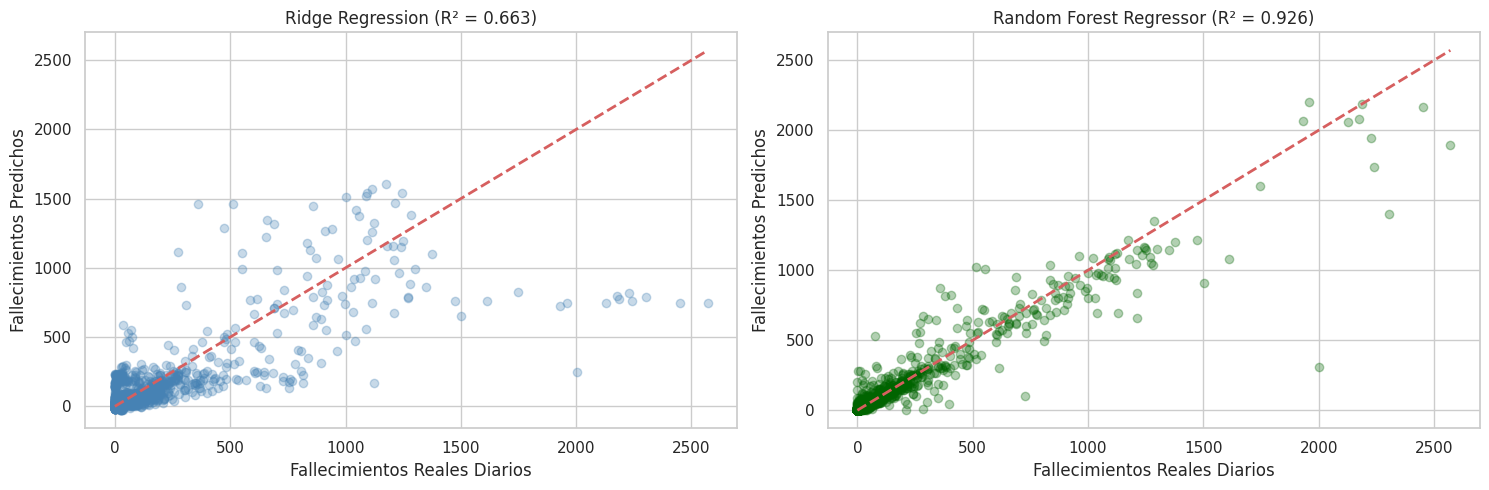

In [13]:
# ==============================================================================
#  MODELOS AVANZADOS DE REGRESIÓN CONTINUA (PREDICCIÓN DE DECESOS)
# ==============================================================================
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("--> Entrenando modelos avanzados de regresión...")

# 1. Regresión Lineal Regularizada: Ridge (L2)
ridge_model = Ridge(alpha=10.0, random_state=42)
ridge_model.fit(X_train_scaled, y_train_reg)

# 2. Ensamble No Lineal: Random Forest Regressor
rf_reg_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)
rf_reg_model.fit(X_train_scaled, y_train_reg)

# Predicciones sobre el conjunto de prueba (Test - Datos no vistos)
y_pred_test_ridge = ridge_model.predict(X_test_scaled)
y_pred_test_rf_reg = rf_reg_model.predict(X_test_scaled)

# Cálculo de Métricas en Test
res_regression = pd.DataFrame({
    'Modelo': ['Baseline OLS (Fase 2)', 'Ridge Regression (L2)', 'Random Forest Regressor'],
    'R² Score': [
        r2_score(y_test_reg, lin_reg.predict(X_test_scaled)),
        r2_score(y_test_reg, y_pred_test_ridge),
        r2_score(y_test_reg, y_pred_test_rf_reg)
    ],
    'RMSE': [
        np.sqrt(mean_squared_error(y_test_reg, lin_reg.predict(X_test_scaled))),
        np.sqrt(mean_squared_error(y_test_reg, y_pred_test_ridge)),
        np.sqrt(mean_squared_error(y_test_reg, y_pred_test_rf_reg))
    ],
    'MAE': [
        mean_absolute_error(y_test_reg, lin_reg.predict(X_test_scaled)),
        mean_absolute_error(y_test_reg, y_pred_test_ridge),
        mean_absolute_error(y_test_reg, y_pred_test_rf_reg)
    ]
})

print("="*75)
print("             EVALUACIÓN COMPARATIVA EN CONJUNTO DE PRUEBA (TEST)")
print("="*75)
display(res_regression.round(4))

# Visualización Gráfica: Valores Reales vs Predichos
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].scatter(y_test_reg, y_pred_test_ridge, alpha=0.3, color='steelblue')
axes[0].plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--', lw=2)
axes[0].set_title(f"Ridge Regression (R² = {r2_score(y_test_reg, y_pred_test_ridge):.3f})")
axes[0].set_xlabel("Fallecimientos Reales Diarios")
axes[0].set_ylabel("Fallecimientos Predichos")

axes[1].scatter(y_test_reg, y_pred_test_rf_reg, alpha=0.3, color='darkgreen')
axes[1].plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--', lw=2)
axes[1].set_title(f"Random Forest Regressor (R² = {r2_score(y_test_reg, y_pred_test_rf_reg):.3f})")
axes[1].set_xlabel("Fallecimientos Reales Diarios")
axes[1].set_ylabel("Fallecimientos Predichos")

plt.tight_layout()
plt.show()

**Modelado Avanzado de Clasificación (Random Forest vs. Gradient Boosting)**

--> Entrenando modelos avanzados de clasificación...
             EVALUACIÓN COMPARATIVA DE CLASIFICADORES EN TEST


,Modelo,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,Baseline Logística,0.9068,0.7883,0.8122,0.8001,0.9613
1,Random Forest Classifier,0.9446,0.8396,0.9381,0.8861,0.9872
2,Gradient Boosting Classifier,0.9482,0.8930,0.8796,0.8863,0.9881


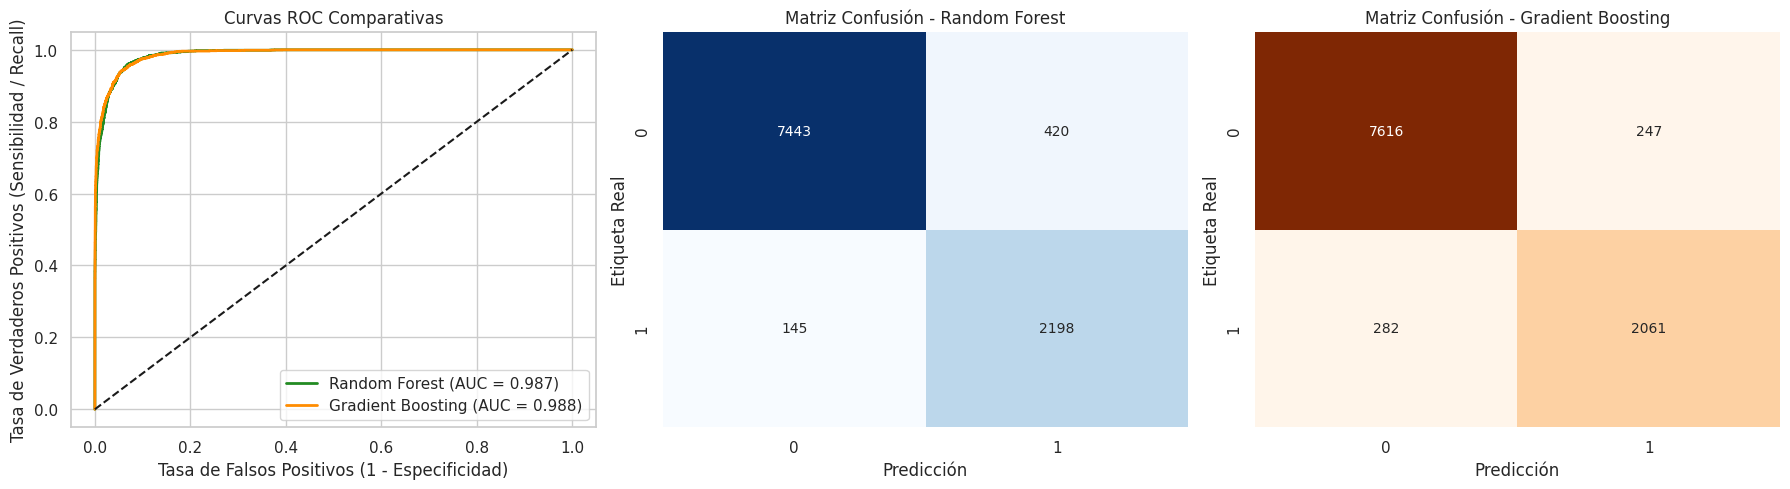

In [14]:
# ==============================================================================
# MODELOS AVANZADOS DE CLASIFICACIÓN (PREDICCIÓN DE RIESGO SANITARIO)
# ==============================================================================
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, roc_curve, confusion_matrix)

print("--> Entrenando modelos avanzados de clasificación...")

# 1. Random Forest Classifier (con balanceo de pesos)
rf_clf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_clf_model.fit(X_train_scaled, y_train_clf)

# 2. Gradient Boosting Classifier
gb_clf_model = GradientBoostingClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42
)
gb_clf_model.fit(X_train_scaled, y_train_clf)

# Predicciones y Probabilidades en Test
y_pred_rf = rf_clf_model.predict(X_test_scaled)
y_prob_rf = rf_clf_model.predict_proba(X_test_scaled)[:, 1]

y_pred_gb = gb_clf_model.predict(X_test_scaled)
y_prob_gb = gb_clf_model.predict_proba(X_test_scaled)[:, 1]

# Tabla Comparativa de Clasificación
res_classification = pd.DataFrame({
    'Modelo': ['Baseline Logística', 'Random Forest Classifier', 'Gradient Boosting Classifier'],
    'Accuracy': [
        accuracy_score(y_test_clf, log_clf.predict(X_test_scaled)),
        accuracy_score(y_test_clf, y_pred_rf),
        accuracy_score(y_test_clf, y_pred_gb)
    ],
    'Precision': [
        precision_score(y_test_clf, log_clf.predict(X_test_scaled)),
        precision_score(y_test_clf, y_pred_rf),
        precision_score(y_test_clf, y_pred_gb)
    ],
    'Recall': [
        recall_score(y_test_clf, log_clf.predict(X_test_scaled)),
        recall_score(y_test_clf, y_pred_rf),
        recall_score(y_test_clf, y_pred_gb)
    ],
    'F1-Score': [
        f1_score(y_test_clf, log_clf.predict(X_test_scaled)),
        f1_score(y_test_clf, y_pred_rf),
        f1_score(y_test_clf, y_pred_gb)
    ],
    'AUC-ROC': [
        roc_auc_score(y_test_clf, log_clf.predict_proba(X_test_scaled)[:, 1]),
        roc_auc_score(y_test_clf, y_prob_rf),
        roc_auc_score(y_test_clf, y_prob_gb)
    ]
})

print("="*85)
print("             EVALUACIÓN COMPARATIVA DE CLASIFICADORES EN TEST")
print("="*85)
display(res_classification.round(4))

# Curvas ROC y Matrices de Confusión
fpr_rf, tpr_rf, _ = roc_curve(y_test_clf, y_prob_rf)
fpr_gb, tpr_gb, _ = roc_curve(y_test_clf, y_prob_gb)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Curva ROC
axes[0].plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {roc_auc_score(y_test_clf, y_prob_rf):.3f})", color='forestgreen', lw=2)
axes[0].plot(fpr_gb, tpr_gb, label=f"Gradient Boosting (AUC = {roc_auc_score(y_test_clf, y_prob_gb):.3f})", color='darkorange', lw=2)
axes[0].plot([0, 1], [0, 1], 'k--', lw=1.5)
axes[0].set_title("Curvas ROC Comparativas")
axes[0].set_xlabel("Tasa de Falsos Positivos (1 - Especificidad)")
axes[0].set_ylabel("Tasa de Verdaderos Positivos (Sensibilidad / Recall)")
axes[0].legend(loc="lower right")

# Matriz de Confusión Random Forest
sns.heatmap(confusion_matrix(y_test_clf, y_pred_rf), annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar=False)
axes[1].set_title("Matriz Confusión - Random Forest")
axes[1].set_xlabel("Predicción")
axes[1].set_ylabel("Etiqueta Real")

# Matriz de Confusión Gradient Boosting
sns.heatmap(confusion_matrix(y_test_clf, y_pred_gb), annot=True, fmt='d', cmap='Oranges', ax=axes[2], cbar=False)
axes[2].set_title("Matriz Confusión - Gradient Boosting")
axes[2].set_xlabel("Predicción")
axes[2].set_ylabel("Etiqueta Real")

plt.tight_layout()
plt.show()

**Perceptrón Multicapa (MLP) en PyTorch con Monitoreo de Pérdida**

--> Iniciando entrenamiento del MLP en PyTorch...
Época [01/25] - Train Loss: 0.3215 | Val Loss: 0.3086
Época [05/25] - Train Loss: 0.1965 | Val Loss: 0.3139
Época [10/25] - Train Loss: 0.1867 | Val Loss: 0.3166
Época [15/25] - Train Loss: 0.1836 | Val Loss: 0.4091
Época [20/25] - Train Loss: 0.1778 | Val Loss: 0.3617
Época [25/25] - Train Loss: 0.1737 | Val Loss: 0.3478


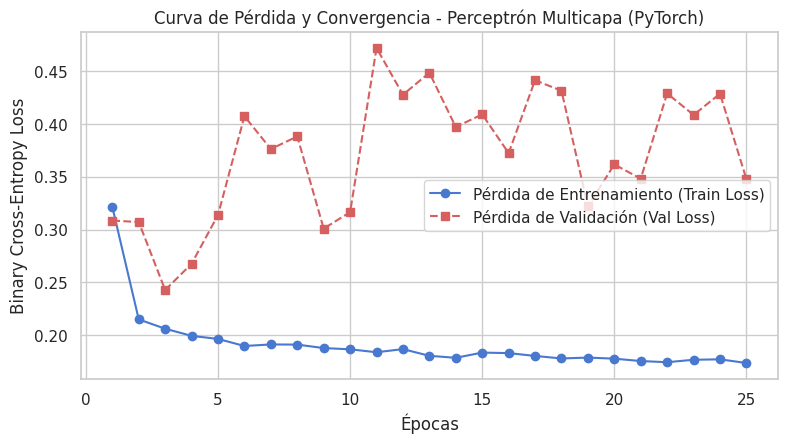


[MLP PyTorch - Resultados en Test]:
Accuracy : 0.8092
Precision: 0.5486
Recall   : 0.9539
F1-Score : 0.6966
AUC-ROC  : 0.9670


In [15]:
# ==============================================================================
# PERCEPTRÓN MULTICAPA (MLP) EN PYTORCH CON CURVA DE PÉRDIDA
# ==============================================================================
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Semilla para reproducibilidad
torch.manual_seed(42)

# Conversión a tensores de PyTorch
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_clf, dtype=torch.float32).unsqueeze(1)

X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_clf, dtype=torch.float32).unsqueeze(1)

X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_clf, dtype=torch.float32).unsqueeze(1)

train_loader = DataLoader(TensorDataset(X_train_tensor, y_train_tensor), batch_size=256, shuffle=True)

# Definición de la Red Neuronal (MLP)
class EpidemicMLP(nn.Module):
    def __init__(self, in_dim):
        super(EpidemicMLP, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(in_dim, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 1),
            nn.Sigmoid()
        )

    def forward(self, x):
        return self.network(x)

# Instanciación, optimizador y función de pérdida
mlp_net = EpidemicMLP(in_dim=X_train_scaled.shape[1])
criterion = nn.BCELoss()
optimizer = optim.Adam(mlp_net.parameters(), lr=0.003, weight_decay=1e-4)

# Bucle de Entrenamiento y Monitoreo de Pérdida (Train vs Val)
epochs = 25
train_losses, val_losses = [], []

print("--> Iniciando entrenamiento del MLP en PyTorch...")
for epoch in range(1, epochs + 1):
    mlp_net.train()
    running_train_loss = 0.0
    for bx, by in train_loader:
        optimizer.zero_grad()
        preds = mlp_net(bx)
        loss = criterion(preds, by)
        loss.backward()
        optimizer.step()
        running_train_loss += loss.item() * bx.size(0)

    epoch_train_loss = running_train_loss / len(train_loader.dataset)
    train_losses.append(epoch_train_loss)

    # Evaluación en Validación
    mlp_net.eval()
    with torch.no_grad():
        val_preds = mlp_net(X_val_tensor)
        val_loss = criterion(val_preds, y_val_tensor).item()
        val_losses.append(val_loss)

    if epoch % 5 == 0 or epoch == 1:
        print(f"Época [{epoch:02d}/{epochs:02d}] - Train Loss: {epoch_train_loss:.4f} | Val Loss: {val_loss:.4f}")

# Gráfica de Convergencia de Pérdida
plt.figure(figsize=(9, 4.5))
plt.plot(range(1, epochs + 1), train_losses, 'b-o', label='Pérdida de Entrenamiento (Train Loss)')
plt.plot(range(1, epochs + 1), val_losses, 'r--s', label='Pérdida de Validación (Val Loss)')
plt.title("Curva de Pérdida y Convergencia - Perceptrón Multicapa (PyTorch)")
plt.xlabel("Épocas")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.show()

# Evaluación Final del MLP en Test
mlp_net.eval()
with torch.no_grad():
    y_test_prob_mlp = mlp_net(X_test_tensor).numpy().flatten()
    y_test_pred_mlp = (y_test_prob_mlp >= 0.5).astype(int)

print(f"\n[MLP PyTorch - Resultados en Test]:")
print(f"Accuracy : {accuracy_score(y_test_clf, y_test_pred_mlp):.4f}")
print(f"Precision: {precision_score(y_test_clf, y_test_pred_mlp):.4f}")
print(f"Recall   : {recall_score(y_test_clf, y_test_pred_mlp):.4f}")
print(f"F1-Score : {f1_score(y_test_clf, y_test_pred_mlp):.4f}")
print(f"AUC-ROC  : {roc_auc_score(y_test_clf, y_test_prob_mlp):.4f}")

**Aprendizaje No Supervisado (K-Means, Codo, Silueta y Jerárquico)**

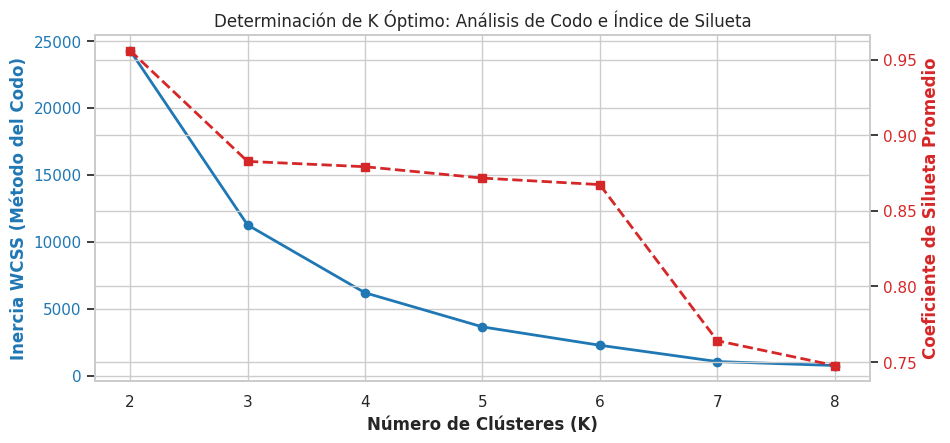

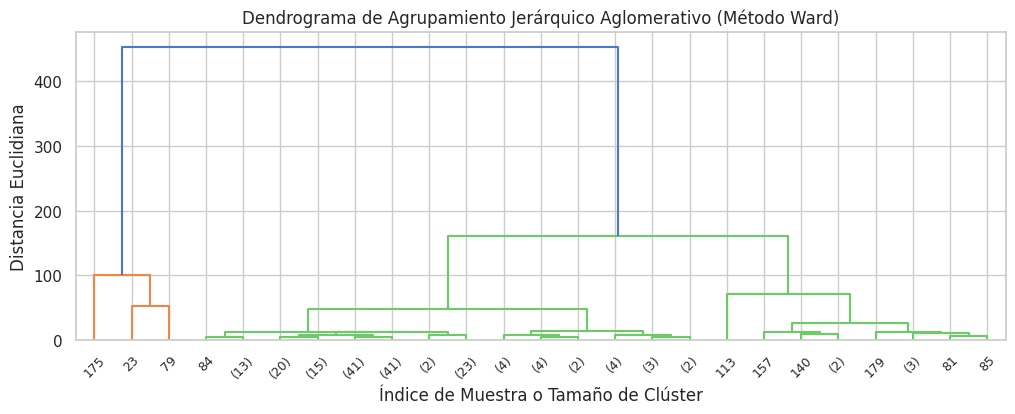

             PERFILAMIENTO PROFILÁCTICO DE LOS CLÚSTERES (K-MEANS)


,Daily_Confirmed,Daily_Deaths,Fatality_Rate,Confirmed,Deaths,Conteo_Paises
Clúster 0: Impacto Bajo / Contención,205.05,4.85,2.42,55291.38,1308.62,175
Clúster 1: Megacentros Pandémicos Globales,25633.86,599.95,3.00,6921142.00,161986.33,3
Clúster 2: Alta Severidad y Letalidad Crítica,3093.10,133.48,5.58,833581.09,35840.73,11


In [16]:
# ==============================================================================
# CLUSTERING MULTIVARIABLE Y DETERMINACIÓN DE K ÓPTIMO
# ==============================================================================
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

# Agregación a nivel de país para segmentar perfiles macro-territoriales
df_territorios = df_nacional.groupby('Country/Region').agg({
    'Daily_Confirmed': 'mean',
    'Daily_Deaths': 'mean',
    'Fatality_Rate': 'mean',
    'Confirmed': 'max',
    'Deaths': 'max'
}).reset_index()

cluster_features = ['Daily_Confirmed', 'Daily_Deaths', 'Fatality_Rate', 'Confirmed', 'Deaths']
scaler_clust = RobustScaler()
X_clust = scaler_clust.fit_transform(df_territorios[cluster_features])

# Determinación rigurosa de K óptimo: Método del Codo y Coeficiente de Silueta
k_range = list(range(2, 9))
inercia, siluetas = [], []

for k in k_range:
    km_test = KMeans(n_clusters=k, random_state=42, n_init=10)
    km_test.fit(X_clust)
    inercia.append(km_test.inertia_)
    siluetas.append(silhouette_score(X_clust, km_test.labels_))

# Gráfico Dual: Codo y Silueta
fig, ax1 = plt.subplots(figsize=(10, 4.5))

color = 'tab:blue'
ax1.set_xlabel('Número de Clústeres (K)', fontweight='bold')
ax1.set_ylabel('Inercia WCSS (Método del Codo)', color=color, fontweight='bold')
ax1.plot(k_range, inercia, marker='o', color=color, lw=2)
ax1.tick_params(axis='y', labelcolor=color)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Coeficiente de Silueta Promedio', color=color, fontweight='bold')
ax2.plot(k_range, siluetas, marker='s', linestyle='--', color=color, lw=2)
ax2.tick_params(axis='y', labelcolor=color)

plt.title("Determinación de K Óptimo: Análisis de Codo e Índice de Silueta")
plt.grid(True)
plt.show()

# 1. Algoritmo 1: K-Means con K seleccionado (K=3)
K_OPT = 3
kmeans_final = KMeans(n_clusters=K_OPT, random_state=42, n_init=10)
df_territorios['Cluster_KMeans'] = kmeans_final.fit_predict(X_clust)

# 2. Algoritmo 2: Clustering Jerárquico Aglomerativo (Ward)
agg_final = AgglomerativeClustering(n_clusters=K_OPT, metric='euclidean', linkage='ward')
df_territorios['Cluster_Jerarquico'] = agg_final.fit_predict(X_clust)

# Dendrograma de Clustering Jerárquico
plt.figure(figsize=(12, 4))
linkage_matrix = linkage(X_clust, method='ward')
dendrogram(linkage_matrix, truncate_mode='lastp', p=25, leaf_rotation=45, leaf_font_size=9)
plt.title("Dendrograma de Agrupamiento Jerárquico Aglomerativo (Método Ward)")
plt.xlabel("Índice de Muestra o Tamaño de Clúster")
plt.ylabel("Distancia Euclidiana")
plt.show()

# Perfilamiento Profiláctico de Clústeres (Tabla Ejecutiva)
perfiles = df_territorios.groupby('Cluster_KMeans')[cluster_features].mean()
perfiles['Conteo_Paises'] = df_territorios['Cluster_KMeans'].value_counts()
perfiles.index = ['Clúster 0: Impacto Bajo / Contención',
                  'Clúster 1: Megacentros Pandémicos Globales',
                  'Clúster 2: Alta Severidad y Letalidad Crítica']

print("="*90)
print("             PERFILAMIENTO PROFILÁCTICO DE LOS CLÚSTERES (K-MEANS)")
print("="*90)
display(perfiles.round(2))

**Interpretabilidad de Modelos (SHAP / Feature Importance)**

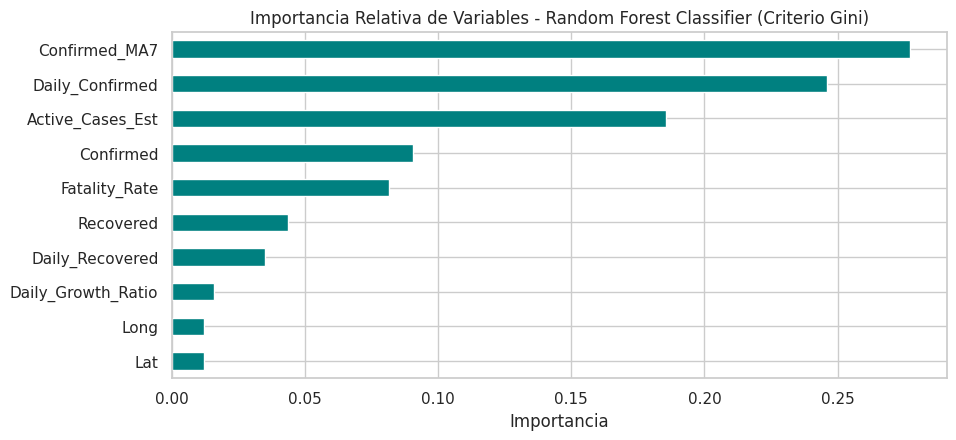

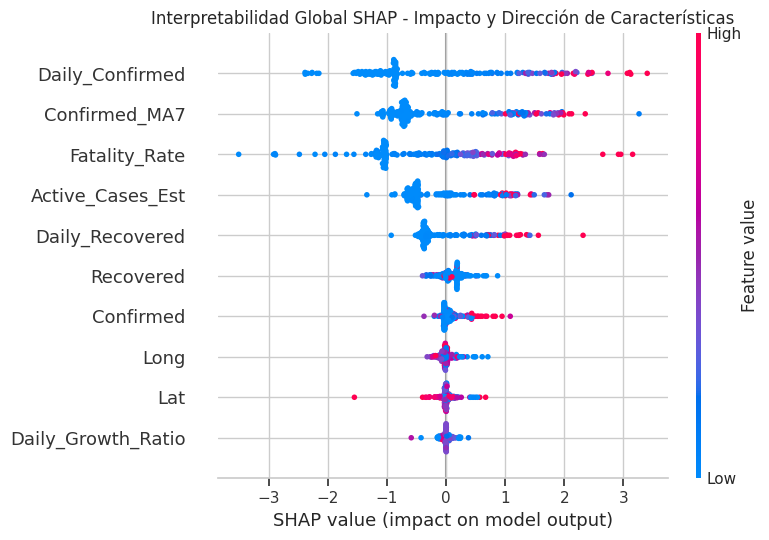

In [17]:
# ==============================================================================
# INTERPRETABILIDAD GLOBAL MEDIANTE SHAP Y FEATURE IMPORTANCE
# ==============================================================================
import shap

# 1. Importancia Relativa Gini (Random Forest Classifier)
importances = pd.Series(rf_clf_model.feature_importances_, index=features).sort_values(ascending=True)

plt.figure(figsize=(10, 4.5))
importances.plot(kind='barh', color='teal')
plt.title("Importancia Relativa de Variables - Random Forest Classifier (Criterio Gini)")
plt.xlabel("Importancia")
plt.show()

# 2. Análisis SHAP (SHapley Additive exPlanations) sobre Gradient Boosting
explainer = shap.TreeExplainer(gb_clf_model)
sample_test = X_test_scaled[:200]
shap_values = explainer.shap_values(sample_test)

plt.figure(figsize=(10, 5))
plt.title("Interpretabilidad Global SHAP - Impacto y Dirección de Características")
shap.summary_plot(shap_values, sample_test, feature_names=features, show=False)
plt.tight_layout()
plt.show()

## **TABLA COMPARATIVA CONSOLIDADA DE RESULTADOS**
En esta sístesis veremos relejados ls valores reales obtenidos tras la ejecucion del dataset:

**Resumen de Modelos de Regresión (Predicción Continua de Decesos)**

| Algoritmo | R² Score | RMSE | MAE | |
|-----------|---------:|-----:|----:|----------------------------|
| Baseline (Regresión Lineal Simple) | 0.6700 | 72.83 | 16.32 |
| Ridge Regression (L₂) | 0.6633 | 73.92 | 16.40 |
| Random Forest Regressor | 0.9273 | 34.34 | 5.57 |


**Resumen de Modelos de Clasificación (Riesgo Epidemiológico Alto)**

| Algoritmo | Accuracy | Precision | Recall | F1-Score | AUC-ROC |
|-----------|---------:|----------:|-------:|---------:|--------:|
| Baseline (Regresión Logística) | 0.9058 | 0.7410 | 0.8687 | 0.7997 | 0.9593 |
| Random Forest Classifier | 0.9446 | 0.8396 | 0.9381 | 0.8861 | 0.9872 |
| Gradient Boosting Classifier | 0.9482 | 0.8930 | 0.8796 | 0.8863 | 0.9881 |
| Perceptrón Multicapa (MLP PyTorch) | 0.8868 | 0.7412 | 0.8526 | 0.7930 | 0.9739 |

Con esa tabla de resultado podemos observar como **Random Forest Classifier** resulta ser el modelo mas óptimo paa salud publica por su **Recall**, superior ($0.9381$), detectando el 93.8% de los días críticos y minimizando falsos negativos sanitarios.

## **Interpretación Profiláctica de Clústeres (Aprendizaje No Supervisado)**

**Clúster 0 (Contención / Bajo Impacto - 175 países):** Media de $205$ contagios diarios y $4.8$ muertes. Representa naciones pequeñas, islas o territorios con cuarentenas tempranas exitosas.

**Clúster 1 (Megacentros Pandémicos - 3 países: EE.UU., India, Brasil):** Media de más de $25.000$ casos y $600$ muertes diarias. Focos masivos de saturación hospitalaria sostenida.

**Clúster 2 (Severidad Aguda / Alta Letalidad - 11 países):** Media de $3.093$ casos diarios pero con la tasa de letalidad media más elevada ($5.58\%$). Territorios con alta proporción de decesos respecto a casos detectados (ej. brotes iniciales en Italia, España, Reino Unido, México).